Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Alpaca credentials loaded successfully.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


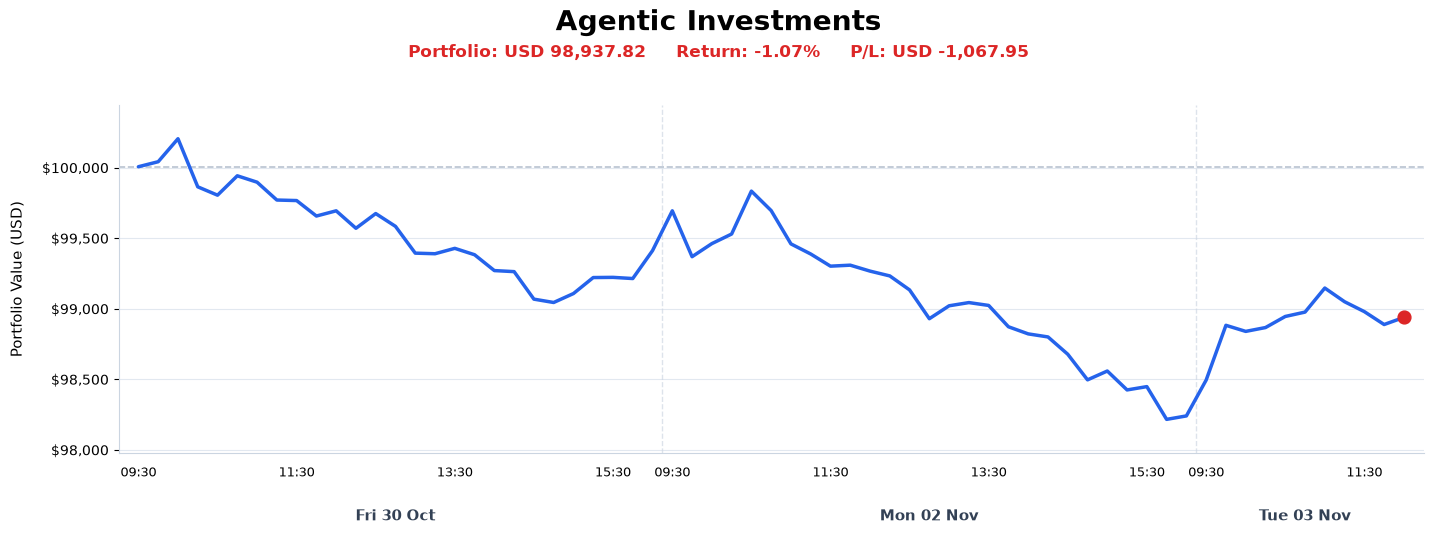

In [10]:
%pip install -U alpaca-py
%pip install python-dotenv
import os
import pandas as pd
import matplotlib.pyplot as plt

from dotenv import load_dotenv, find_dotenv
from matplotlib.ticker import FuncFormatter
from datetime import datetime
from zoneinfo import ZoneInfo

from alpaca.trading.client import TradingClient
from alpaca.trading.requests import GetPortfolioHistoryRequest

# -----------------------------------
# 0. Load API credentials from .env
# -----------------------------------

env_path = find_dotenv(usecwd=True)

if not env_path:
    raise FileNotFoundError(
        "Could not find .env in the current directory or its parents."
    )

load_dotenv(env_path)

api_key = os.getenv("ALPACA_API_KEY")
secret_key = os.getenv("ALPACA_SECRET_KEY")

if not api_key or not secret_key:
    raise ValueError(
        "ALPACA_API_KEY or ALPACA_SECRET_KEY missing from .env"
    )

print("Alpaca credentials loaded successfully.")

# -----------------------------------
# 1. Fetch portfolio data
# -----------------------------------

client = TradingClient(
    api_key,
    secret_key,
    paper=True
)

ny = ZoneInfo("America/New_York")

history = client.get_portfolio_history(
    GetPortfolioHistoryRequest(
        start=datetime(2026, 10, 30, tzinfo=ny),
        end=datetime.now(ny),
        timeframe="15Min",
        intraday_reporting="market_hours"
    )
)

# -----------------------------------
# 2. Prepare data
# -----------------------------------

df = pd.DataFrame({
    "time": pd.to_datetime(
        history.timestamp, unit="s", utc=True
    ).tz_convert(ny),
    "equity": history.equity
})

df["equity"] = pd.to_numeric(
    df["equity"],
    errors="coerce"
)

df = (
    df.dropna()
    .sort_values("time")
    .drop_duplicates(subset="time")
    .reset_index(drop=True)
)

if df.empty:
    raise ValueError("No portfolio history available.")

df["date"] = df["time"].dt.date

# Compress nights and weekends
# Each observation gets the next X position
df["x"] = range(len(df))

# -----------------------------------
# 3. Calculate performance
# -----------------------------------

initial = df["equity"].iloc[0]
current = df["equity"].iloc[-1]

profit = current - initial

return_pct = (
    (profit / initial) * 100
    if initial != 0
    else 0.0
)

# -----------------------------------
# 4. Create one continuous graph
# -----------------------------------

fig, ax = plt.subplots(figsize=(15, 6))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# ONE continuous line across all days
ax.plot(
    df["x"],
    df["equity"],
    color="#2563eb",
    linewidth=2.5,
    solid_capstyle="round",
    zorder=3
)

# Starting value reference
ax.axhline(
    initial,
    color="#94a3b8",
    linestyle="--",
    linewidth=1.2,
    alpha=0.65
)

# Highlight last value
point_color = (
    "#16a34a"
    if profit >= 0
    else "#dc2626"
)

ax.scatter(
    df["x"].iloc[-1],
    current,
    color=point_color,
    s=85,
    zorder=5
)

# -----------------------------------
# 5. X-axis: dates and times
# -----------------------------------

tick_positions = []
tick_labels = []

for day, group in df.groupby("date", sort=True):

    first_x = group["x"].iloc[0]
    last_x = group["x"].iloc[-1]
    middle_x = (first_x + last_x) / 2

    # Light separator between trading days
    if first_x > 0:
        ax.axvline(
            first_x - 0.5,
            color="#cbd5e1",
            linestyle="--",
            linewidth=1,
            alpha=0.65
        )

    # Time labels: roughly every two hours
    for i in range(0, len(group), 8):
        row = group.iloc[i]

        tick_positions.append(row["x"])
        tick_labels.append(
            row["time"].strftime("%H:%M")
        )

    # Center date underneath each trading day
    date_label = pd.Timestamp(day).strftime(
        "%a %d %b"
    )

    ax.text(
        middle_x,
        -0.16,
        date_label,
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="top",
        fontsize=11,
        fontweight="bold",
        color="#334155"
    )

ax.set_xticks(tick_positions)
ax.set_xticklabels(
    tick_labels,
    fontsize=9
)

ax.tick_params(
    axis="x",
    length=0,
    pad=10
)

ax.set_xlim(-1, len(df))

# -----------------------------------
# 6. Y-axis and styling
# -----------------------------------

min_value = df["equity"].min()
max_value = df["equity"].max()

padding = max(
    (max_value - min_value) * 0.12,
    50
)

ax.set_ylim(
    min_value - padding,
    max_value + padding
)

ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda x, _: f"${x:,.0f}"
    )
)

ax.set_ylabel(
    "Portfolio Value (USD)",
    fontsize=11,
    labelpad=12
)

ax.grid(
    axis="y",
    color="#e2e8f0",
    linewidth=0.8
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#cbd5e1")
ax.spines["bottom"].set_color("#cbd5e1")

# -----------------------------------
# 7. Title and performance summary
# -----------------------------------

fig.suptitle(
    "Agentic Investments",
    fontsize=20,
    fontweight="bold",
    y=0.97
)

fig.text(
    0.5,
    0.89,
    f"Portfolio: USD {current:,.2f}     "
    f"Return: {return_pct:+.2f}%     "
    f"P/L: USD {profit:+,.2f}",
    ha="center",
    fontsize=12,
    color=point_color,
    fontweight="bold"
)

fig.subplots_adjust(
    top=0.81,
    bottom=0.23,
    left=0.10,
    right=0.97
)

plt.show()
